In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.interpolate import interp1d
import statistics as stats
import numpy as np

In [2]:
ub_DFBA = pd.read_csv('UB_Bootstraping_DFBA.csv')
lb_DFBA = pd.read_csv('LB_Bootstraping_DFBA.csv')
mean_DFBA = pd.read_csv('Mean_Bootstraping_DFBA.csv')

ub_DFNA = pd.read_csv('UB_Bootstraping_DFNA.csv')
lb_DFNA = pd.read_csv('LB_Bootstraping_DFNA.csv')
mean_DFNA = pd.read_csv('Mean_Bootstraping_DFNA.csv')

data_exp = pd.read_csv('Experiment_1.csv')

In [3]:
palette = sns.color_palette("plasma", 8)
color1  = palette[0]
color2  = sns.color_palette("plasma", 20)[-3]
color3  = palette[2]
color4  = palette[-2]

variables = ['Biomass', 'Glucose', 'Fructose', 'Ethanol', 'Ammonia', 'PAN']
ylabels = ['Biomass (g/L)', 'Glucose (g/L)', 'Fructose (g/L)', 'Ethanol (g/L)', 'Ammonia (g/L)', 'PAN (g/L)']

In [4]:
# Calcula el RMSE para todos los compuestos y muestra una tabla
results = []
for var, ylabel in zip(variables, ylabels):
    mask = ~data_exp[var].isna()
    x_exp = data_exp.loc[mask, 'Time']
    y_exp = data_exp.loc[mask, var]
    interp_DFBA = interp1d(mean_DFBA['Time'], mean_DFBA[var], kind='linear', fill_value='extrapolate')
    interp_DFNA = interp1d(mean_DFNA['Time'], mean_DFNA[var], kind='linear', fill_value='extrapolate')
    y_model_DFBA = interp_DFBA(x_exp)
    y_model_DFNA = interp_DFNA(x_exp)
    rmse_DFBA = np.sqrt(np.mean((y_model_DFBA - y_exp) ** 2))
    rmse_DFNA = np.sqrt(np.mean((y_model_DFNA - y_exp) ** 2))
    results.append({'Compuesto': ylabel, 'RMSE DFBA': rmse_DFBA, 'RMSE DFNA': rmse_DFNA})

tabla_errores = pd.DataFrame(results)
print(tabla_errores)


        Compuesto  RMSE DFBA  RMSE DFNA
0   Biomass (g/L)   0.575679   0.487735
1   Glucose (g/L)   9.265294   6.688006
2  Fructose (g/L)   7.067471   6.432427
3   Ethanol (g/L)  23.616648   4.368187
4   Ammonia (g/L)   0.021235   0.010584
5       PAN (g/L)   0.049597   0.024629


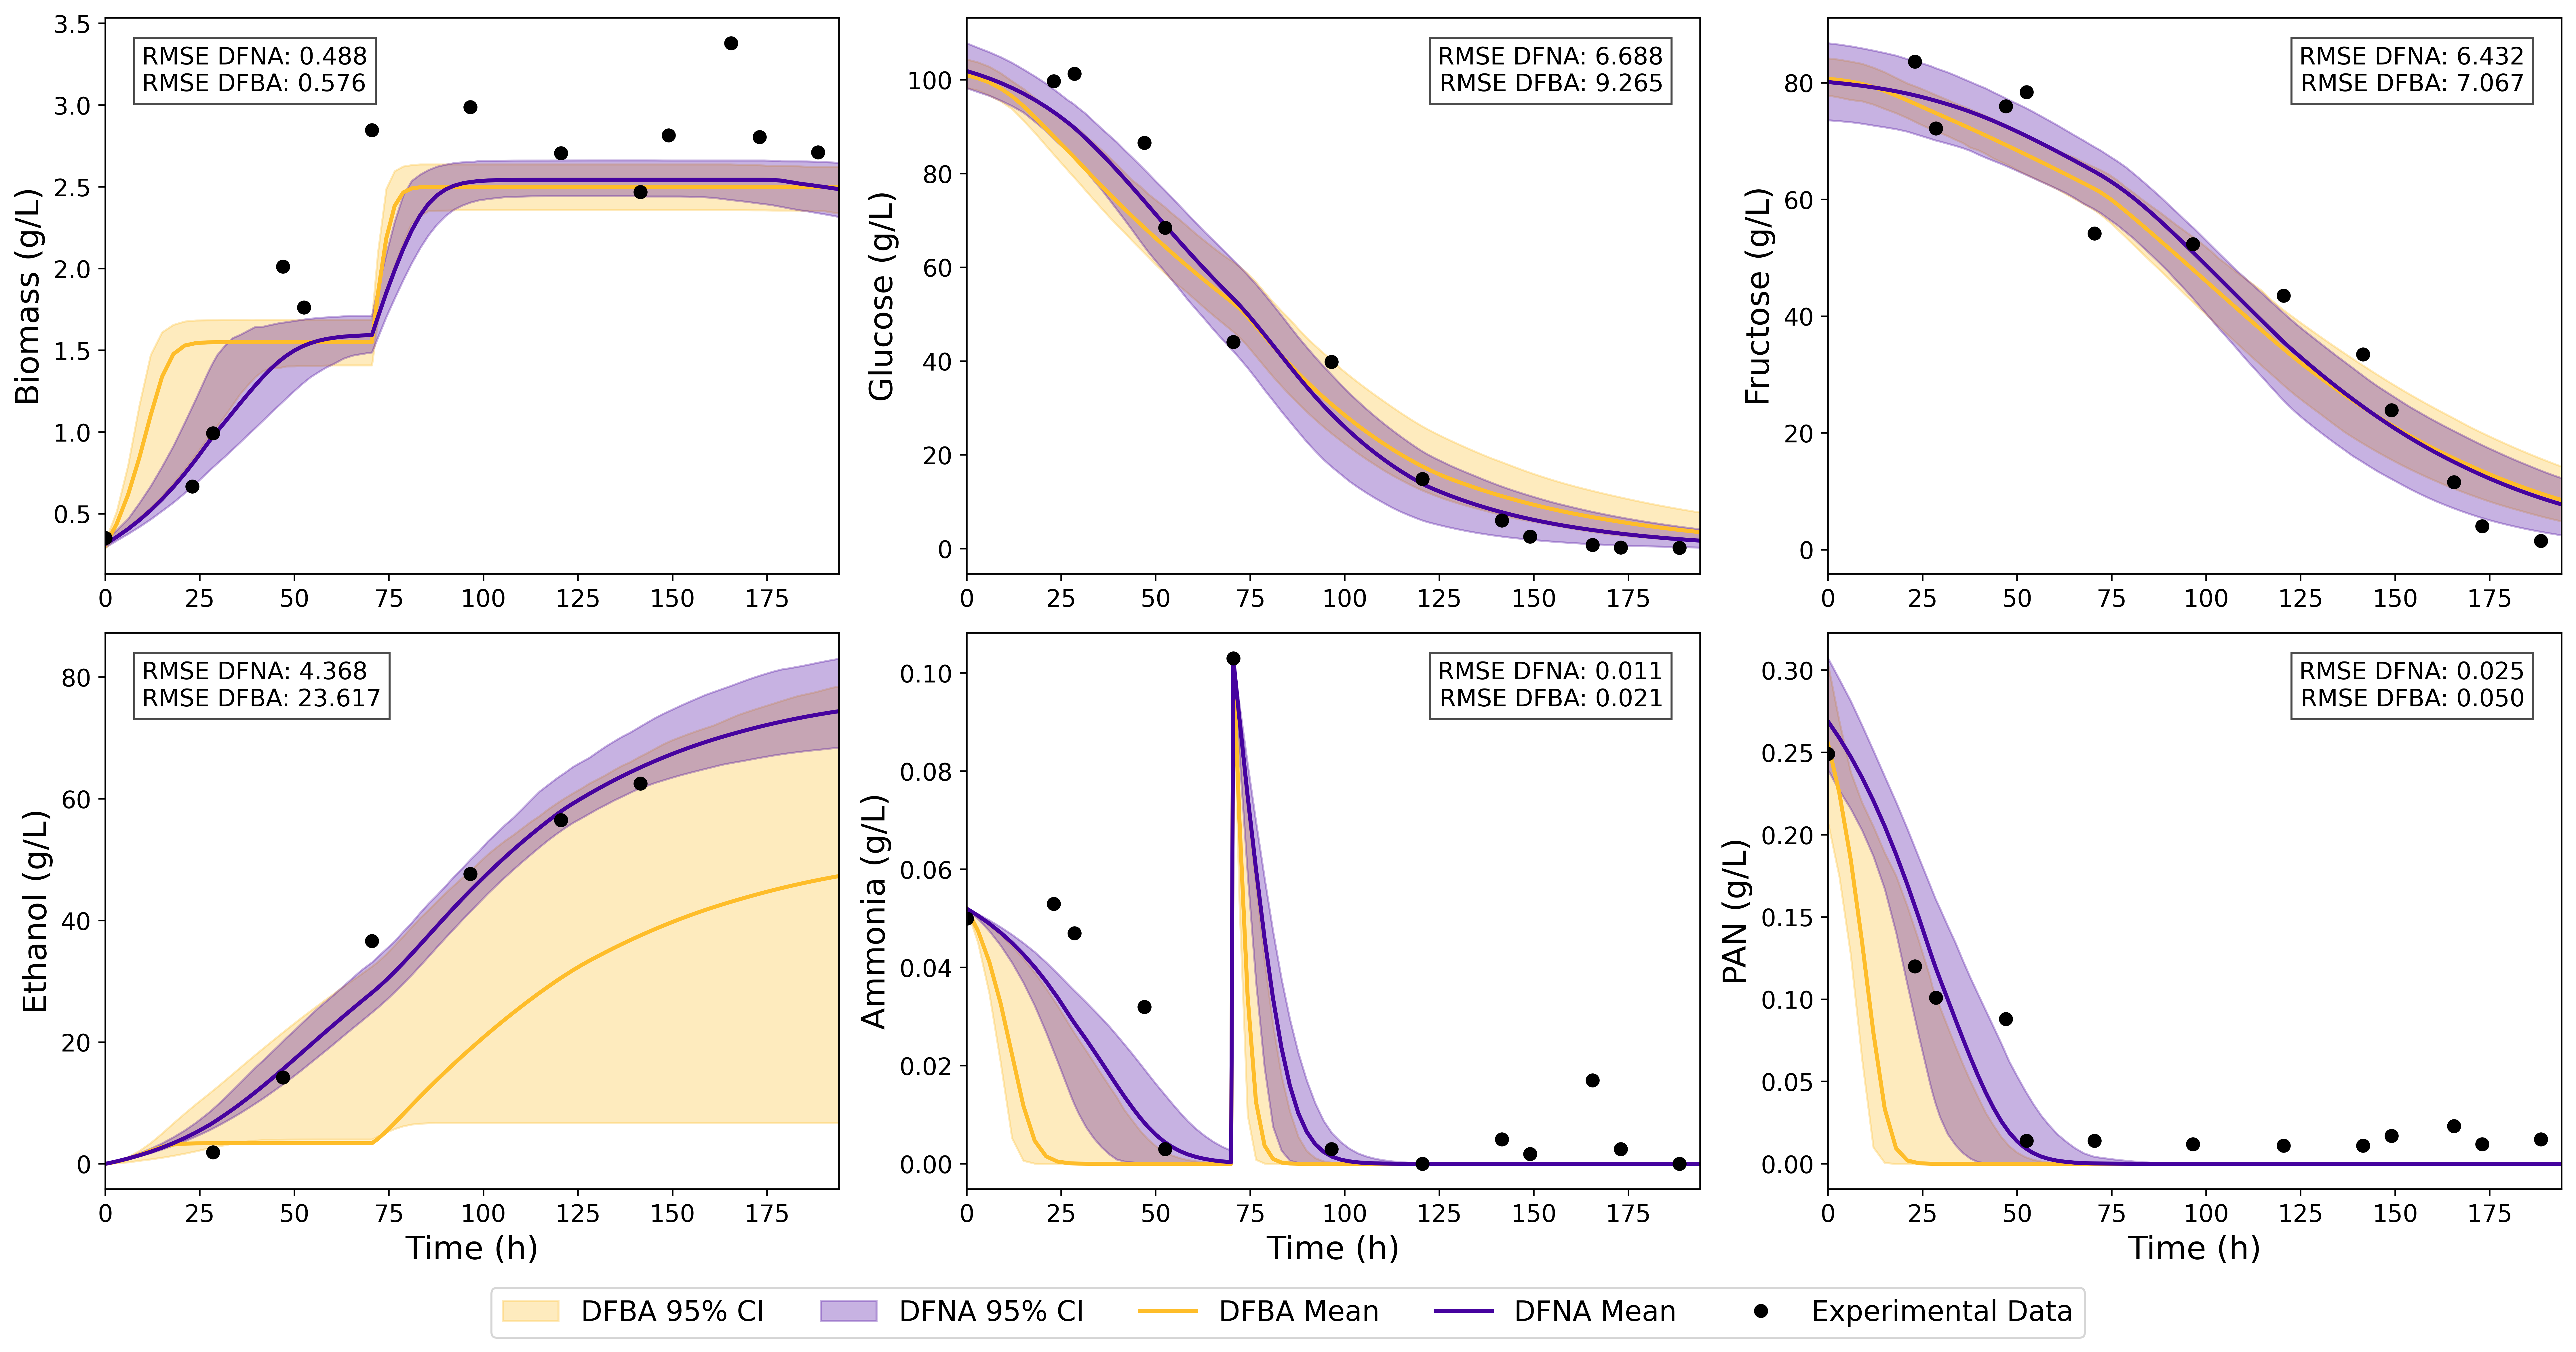

In [5]:
fontsize_labels = 16
fontsize_legend = 14
fontsize_ticks  = 12

fig, axes = plt.subplots(2, 3, figsize=(18, 9), dpi=500)

for idx, (ax, var, ylabel) in enumerate(zip(axes.flat, variables, ylabels)):
    ax.fill_between(lb_DFBA['Time'], lb_DFBA[var], ub_DFBA[var], color=color2, alpha=0.3, label='DFBA 95% CI')
    ax.fill_between(lb_DFNA['Time'], lb_DFNA[var], ub_DFNA[var], color=color1, alpha=0.3, label='DFNA 95% CI')
    ax.plot(mean_DFBA['Time'], mean_DFBA[var], color=color2, label='DFBA Mean', linewidth=2)
    ax.plot(mean_DFNA['Time'], mean_DFNA[var], color=color1, label='DFNA Mean', linewidth=2)
    ax.plot(data_exp['Time'], data_exp[var], 'o', color='black', label='Experimental Data')
    ax.set_xlim(0, 194)
    ax.set_ylabel(ylabel, fontsize=fontsize_labels)
    ax.tick_params(axis='both', which='major', labelsize=fontsize_ticks)

    # Añadir RMSE en cada panel
    rmse_dfba = tabla_errores.loc[idx, 'RMSE DFBA']
    rmse_dfna = tabla_errores.loc[idx, 'RMSE DFNA']

    if var not in ["Biomass","Ethanol"]:
        ax.text(0.95, 0.95, f'RMSE DFNA: {rmse_dfna:.3f}\nRMSE DFBA: {rmse_dfba:.3f}',
        transform=ax.transAxes, fontsize=12, verticalalignment='top', horizontalalignment='right',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='k'))
    else:
        ax.text(0.05, 0.95, f'RMSE DFNA: {rmse_dfna:.3f}\nRMSE DFBA: {rmse_dfba:.3f}',
        transform=ax.transAxes, fontsize=12, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='k'))

    if var in ['Ethanol', 'Ammonia', 'PAN']:
        ax.set_xlabel('Time (h)', fontsize=fontsize_labels)

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=5, fontsize=fontsize_legend)
plt.tight_layout()
# plt.savefig('../Figs/Calibration_CyT.pdf', bbox_inches='tight')
plt.show()

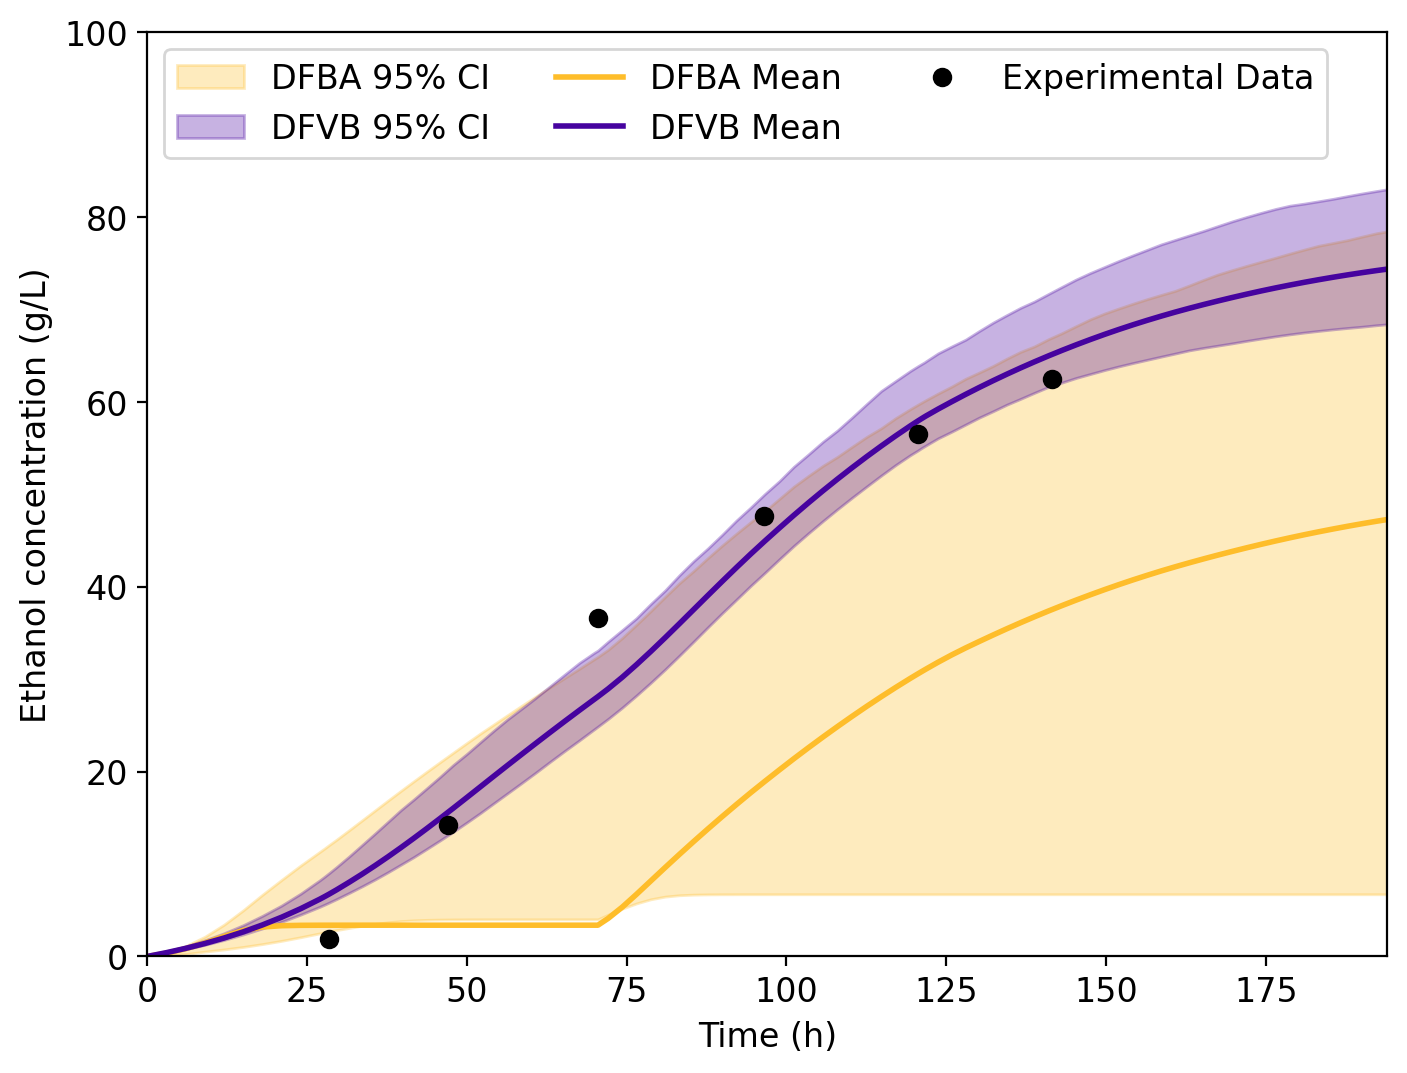

In [25]:
plt.figure(figsize=(8, 6), dpi=200)
plt.fill_between(lb_DFBA['Time'], lb_DFBA['Ethanol'], ub_DFBA['Ethanol'], color=color2, alpha=0.3, label='DFBA 95% CI')
plt.fill_between(lb_DFNA['Time'], lb_DFNA['Ethanol'], ub_DFNA['Ethanol'], color=color1, alpha=0.3, label='DFVB 95% CI')
plt.plot(mean_DFBA['Time'], mean_DFBA['Ethanol'], color=color2, label='DFBA Mean', linewidth=2)
plt.plot(mean_DFNA['Time'], mean_DFNA['Ethanol'], color=color1, label='DFVB Mean', linewidth=2)
plt.plot(data_exp['Time'], data_exp['Ethanol'], 'o', color='black', label='Experimental Data')
plt.legend(loc='upper left', fontsize=12, ncol=3)
plt.xlim(0, 194)
plt.ylim(0, 100)
plt.ylabel('Ethanol concentration (g/L)', fontsize=12)
plt.xlabel('Time (h)', fontsize=12)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.savefig('../Figs/Example_calibration.svg', bbox_inches='tight')

In [6]:
variables

['Biomass', 'Glucose', 'Fructose', 'Ethanol', 'Ammonia', 'PAN']

## Parameter Analysis

In [21]:
parameter_dfba = pd.read_csv("Bootstraping_params_DFBA_CYT.csv")
parameter_dfna = pd.read_csv("Bootstraping_params_DFNA_CYT.csv")

name_parameters = ['X_0', 'N_0', 'G_0', 'F_0', 'E_0', 'PAN_0',
                   r'\mu_0', 'K_n0', 'K_g0', 'K_f0', 'K_ie0', 'Y_xn', 'Y_xg', 'Y_xf', 'Y_ef', r'\beta_f0', r'\beta_ie0']

In [23]:
def ci_width_over_mean(df):
    num = df.select_dtypes(include=[np.number])
    n = num.count()
    means = num.mean()
    stds = num.std(ddof=1)
    se = stds / np.sqrt(n)
    ci_lower = means - 1.96 * se
    ci_upper = means + 1.96 * se
    ci_width = 2 * 1.96 * se
    ratio = ci_width / means.replace(0, 1)  # evita división por cero
    return pd.DataFrame({
        "n": n,
        "mean": means,
        "std": stds,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "ci_width_over_mean": ratio
    })

# Uso
ci_dfba = ci_width_over_mean(parameter_dfba)
ci_dfna = ci_width_over_mean(parameter_dfna)

ci_dfna.index = name_parameters
ci_dfba.index = name_parameters

comparacion_df = pd.DataFrame({
    'mean_dfba': ci_dfba['mean'],
    'std_dfba': ci_dfba['std'],
    # 'ci_lower_dfba': ci_dfba['ci_lower'],
    # 'ci_upper_dfba': ci_dfba['ci_upper'],
    'ci_width_over_mean_dfba': ci_dfba['ci_width_over_mean'],
    'mean_dfna': ci_dfna['mean'],
    'std_dfna': ci_dfna['std'],
    # 'ci_lower_dfna': ci_dfna['ci_lower'],
    # 'ci_upper_dfna': ci_dfna['ci_upper'],
    'ci_width_over_mean_dfna': ci_dfna['ci_width_over_mean']
})
comparacion_df

,mean_dfba,std_dfba,ci_width_over_mean_dfba,mean_dfna,std_dfna,ci_width_over_mean_dfna
X_0,0.306592,0.011281,0.004561,0.314305,0.011490,0.004532
N_0,0.051999,0.000005,0.000011,0.051997,0.000007,0.000017
G_0,100.952334,1.477013,0.001814,101.846852,2.280099,0.002775
F_0,80.684225,1.676288,0.002575,80.121469,3.370789,0.005215
E_0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
PAN_0,0.255201,0.025886,0.012574,0.268765,0.016656,0.007682
\mu_0,0.783388,0.108785,0.017214,0.670369,0.104979,0.019412
K_n0,0.121607,0.033162,0.033804,0.109227,0.036756,0.041714
K_g0,169.605718,26.263660,0.019196,152.393561,28.920155,0.023524
K_f0,177.560867,28.118535,0.019631,182.173913,39.955159,0.027188
